In [1]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute import impute_slice_fgw_barycenter, align_by_pca
from metrics import cluster_compute_ari_and_plot
from prepare_aging import prepare_data

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar
import downstream
import torch

# if torch.cuda.is_available():
#     from objective_cuda import solve_V_all_slices_torch as solve_V_all_slices
# else:
#     from objective import solve_V_all_slices
from objective import solve_V_all_slices

%load_ext autoreload
%autoreload 2

In [2]:
data_dir = "../../../Data/Aging"
adata_all, pd_B, timepoints = prepare_data(data_dir=data_dir, reference='cells')

/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_aging.py:246: FutureWarning: The function read_loom is deprecated and will be removed in the future. Deprecated in favor of other formats, e.g. (`write_h5ad` and then) `read_h5ad`. Loom isn’t well-maintained and supports only a subset of anndata features.
  ref_obj = sc.read_loom(os.path.join(data_dir, "l5_all.agg.loom"))
/home/zhaow/miniforge3/lib/python3.13/site-packages/anndata/_io/read.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  axis_df[k] = v
/home/zhaow/miniforge3/lib/python3.13/site-packages/anndata/_io/read.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns 

In [4]:
seed = 0
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

V, pi, aux = solve_V_all_slices(
                        adata_all, pd_B,
                        verbose=True,
                        ot_solver='low_rank',
                        alpha = 0.5,
                        # k=100, 
                        sparsify = True,
                    )

lambda used = 2.061141e+05 (auto)
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iteration: 50
Iteration: 75
Iteration: 0
Iteration: 25
Iter

In [5]:
import anndata as ad
import matplotlib.pyplot as plt
ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_all),
            celltype_key="celltype",
            embedding_key="spatial",
            clustering="leiden",
            plot=False, 
            auto_resolution=True,
            random_state = 0
            # resolution_grid = np.linspace(0.01, 0.5, 3)

) 

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_all])
for i, adt in enumerate(adata_all):
    adt.obs['pred_label_matchk'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))


# ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
#             np.vstack(V),
#             ad.concat(adata_all),
#             celltype_key="celltype",
#             embedding_key="spatial",
#             clustering="leiden",
#             plot=False, 
#             auto_resolution=False,
#             # resolution_grid = np.linspace(0.01, 0.5, 3)

# ) 

# n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_all])
# for i, adt in enumerate(adata_all):
#     adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

# print('ari='+str(ari))
# print('nmi='+str(nmi))

clustering at resolution=0.01 has been done! Found 2 clusters.
clustering at resolution=1.2 has been done! Found 43 clusters.
clustering at resolution=0.605 has been done! Found 26 clusters.
clustering at resolution=0.3075 has been done! Found 15 clusters.
clustering at resolution=0.45625 has been done! Found 20 clusters.
clustering at resolution=0.38187499999999996 has been done! Found 17 clusters.
clustering at resolution=0.4190625 has been done! Found 18 clusters.
Leiden: target_k=18, best_resolution=0.419, n_clusters=18
ari=0.5487538824435195
nmi=0.6907463602396189


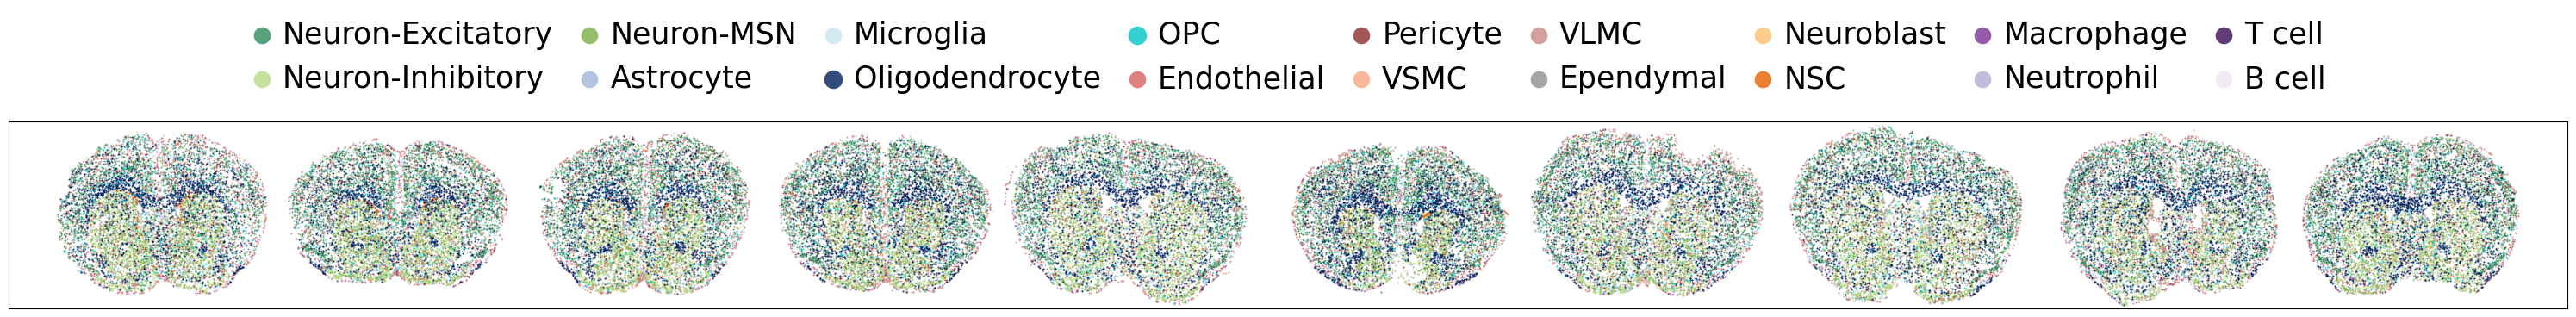

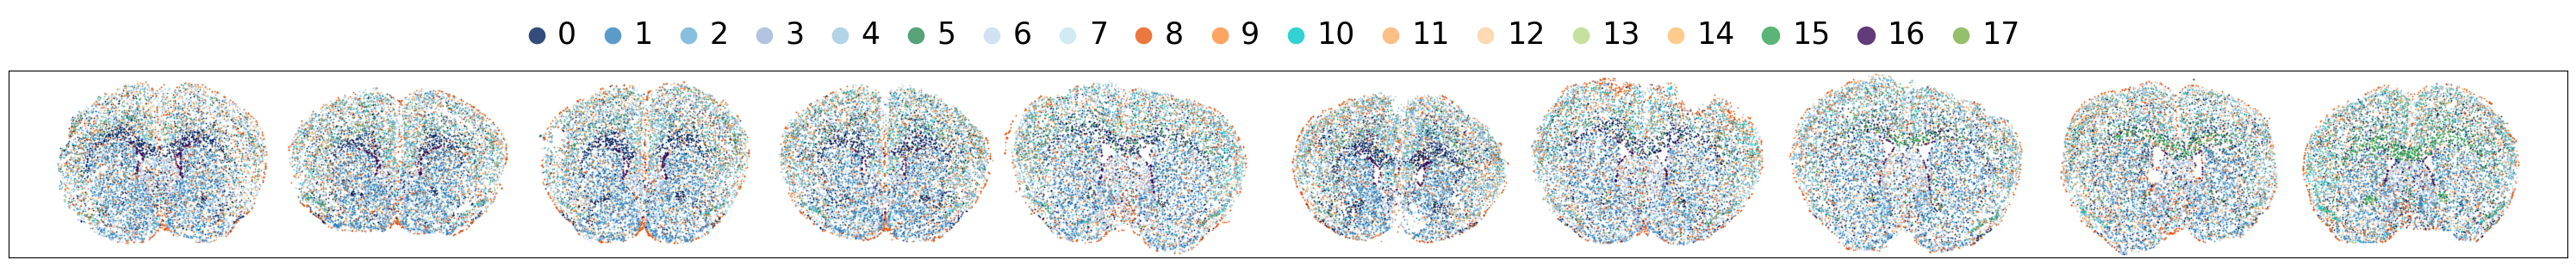

In [6]:


import matplotlib.colors as mcolors
cell_type_colors = {
    # Neurons — keep layer / anatomical structure visible
    "Neuron-Excitatory": "#2E8B57",  # medium green
    "Neuron-Inhibitory": "#B8D986",  # pale yellow-green
    "Neuron-MSN":        "#7BAF45",  # olive green for striatum

    # Glia — Oligo/OPC emphasized
    "Astrocyte":         "#9FB6D9",  # muted pale blue
    "Microglia":         "#C7E7EF",  # very pale cyan
    "Oligodendrocyte":   "#001F5B",
    "OPC":               "#00C7C7",  # bright teal

    # Vasculature — visible but less dominant
    "Endothelial":       "#D95F5F",
    "Pericyte":          "#8C2D2D",
    "VSMC":              "#F4A582",
    "VLMC":              "#C98A85",

    # Other structural
    "Ependymal":         "#8F8F8F",

    # Neurogenic — orange but not too loud
    "Neuroblast":        "#FDBF6F",
    "NSC":               "#E66101",

    # Immune — push into background except macrophage
    "Macrophage":        "#7B3294",
    "Neutrophil":        "#B2ABD2",
    "T cell":            "#3B0A57",#"#D8C6E6",
    "B cell":            "#EEE5F3",
}

cell_types = list(cell_type_colors.keys())
colors_18  = list(cell_type_colors.values())
cmap = mcolors.ListedColormap(colors_18, name="brain_celltypes")

for t in range(len(adata_all)):
    adata_all[t].obs['x'], adata_all[t].obs['y'] = adata_all[t].obsm['spatial'][:,0], adata_all[t].obsm['spatial'][:,1]

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_all[1::2],
    obs_key="celltype",
    obsm_key="spatial",         
    y_scale=1.0,
    x_gap = 1050,
    s=2,
    alpha = 0.8,
    legend_loc='upper center',
    legend_bbox=(0.5,0.9),
    legend_ncol = 9,
    legend_font=25,
    truth_key="celltype",
    truth_cmap=cmap,
    legend_markerscale=10,
    highlight_labels=['Oligodendrocyte','OPC'],
    highlight_size_factor=1.2,
)
plt.show()

# fig, ax = plot_slices_horizontal_centered(
#     adata_list=adata_all[1::2],
#     obs_key="pred_label",
#     obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
#     y_scale=1.0,
#     x_gap = 1050,
#     s=2,
#     alpha = 0.8,
#     legend=True,
#     legend_bbox=(0.1,0.75),
#     legend_ncol = 21,
#     legend_font=25,
#     truth_key="celltype",
#     truth_cmap=cmap,
#     legend_markerscale=10,
# )
# plt.show()

cell_type_colors = {
    # Neurons — keep layer / anatomical structure visible
    5: "#2E8B57",  # medium green
    13: "#B8D986",  # pale yellow-green
    17:        "#7BAF45",  # olive green for striatum

    # Glia — Oligo/OPC emphasized
    3:         "#9FB6D9",  # muted pale blue
    7:         "#C7E7EF",  # very pale cyan
    0:                  "#001F5B",
    10:               "#00C7C7",  # bright teal

    # Vasculature — visible but less dominant
    "Endothelial":       "#D95F5F",
    "Pericyte":          "#8C2D2D",
    "VSMC":              "#F4A582",
    "VLMC":              "#C98A85",

    # Other structural
    "Ependymal":         "#8F8F8F",

    # Neurogenic — orange but not too loud
    14:        "#FDBF6F",
    "NSC":               "#E66101",

    # Immune — push into background except macrophage
    "Macrophage":        "#7B3294",
    "Neutrophil":        "#B2ABD2",
    16:            "#3B0A57",#"#D8C6E6",
    "B cell":            "#EEE5F3",
}

cell_types = list(cell_type_colors.keys())
colors_18  = list(cell_type_colors.values())
cmap = mcolors.ListedColormap(colors_18, name="brain_celltypes")

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_all[1::2],
    obs_key="pred_label_matchk",
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    y_scale=1.0,
    x_gap = 1050,
    s=2,
    alpha = 0.8,
    legend=True,
    legend_bbox=(0.2,0.75),
    legend_ncol = 21,
    legend_font=25,
    color_map = cell_type_colors,
    highlight_labels=[15, 16],
    highlight_size_factor=1.2,
    # truth_key="pred_label_matchk",
    # truth_cmap=cmap,
    legend_markerscale=10,
)
plt.show()


# Some downstream analysis

In [7]:
from plot_utils import plot_V_dotplot_from_adata
from downstream import region_de_wilcoxon, clean_gene_for_enrichr, plot_gene_lollipop_by_region
from downstream import make_gene_name_table, add_parsed_gene_names_to_de

## Task 1 (straightforward): temporal variation in the population and cell type program magnitude varying over time

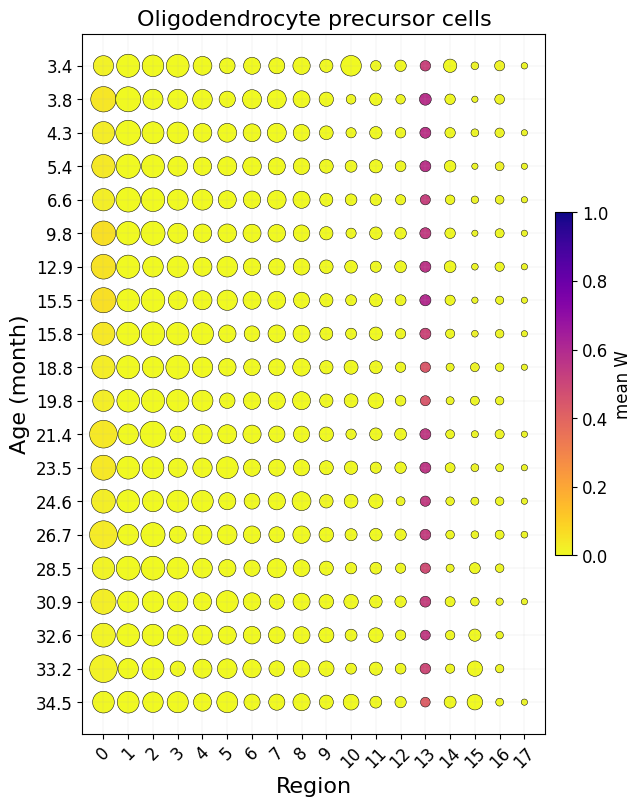

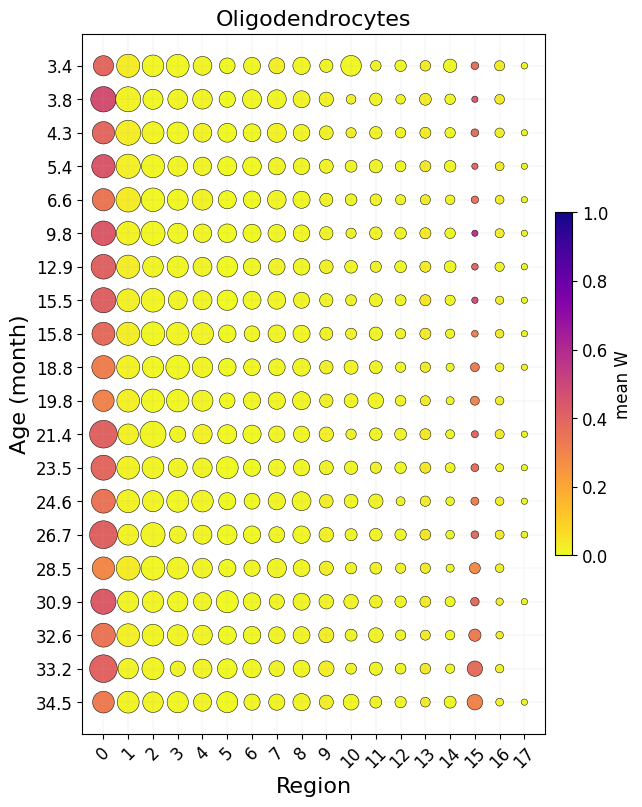

In [8]:
plt.rcParams['font.size'] = 12
celltype_order = pd_B.index.to_list()

fig = plt.figure(figsize=(7,10))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])   # [left, bottom, width, height]

fig = plot_V_dotplot_from_adata(
    adata_list=adata_all,
    V_list=V,
    celltype="Oligodendrocyte precursor cells",
    celltype_names=celltype_order,
    region_key="pred_label_matchk",
    times=[str(t) for t in timepoints],
    agg="mean",
    cmap="plasma_r",
    ax = ax,
    time_name = 'Age (month)',
    # box_threshold = 0.4
)

fig = plt.figure(figsize=(7,10))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])   # [left, bottom, width, height]

fig = plot_V_dotplot_from_adata(
    adata_list=adata_all,
    V_list=V,
    celltype="Oligodendrocytes",
    celltype_names=celltype_order,
    region_key="pred_label_matchk",
    times=[str(t) for t in timepoints],
    agg="mean",
    cmap="plasma_r",
    ax = ax,
     time_name = 'Age (month)',
    #  box_threshold = 0.4
)

# We can look at where these clusters are located

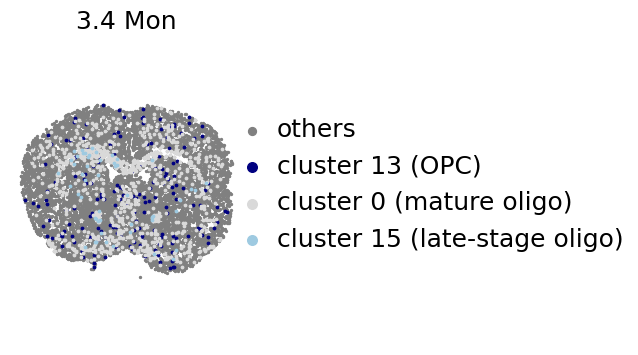

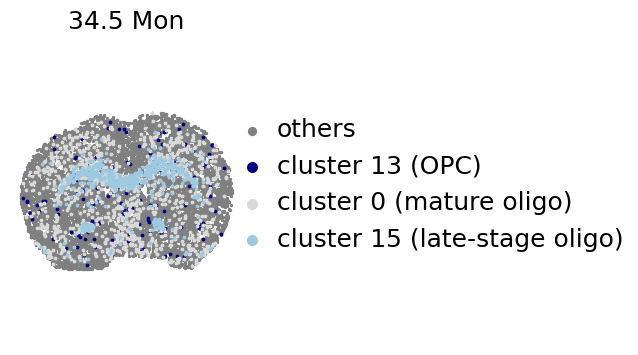

In [10]:
plt.rcParams['figure.figsize'] = (3,4)
cmap = plt.get_cmap("tab20c")
colors = cmap(np.linspace(0, 11/20, 20))

regions_of_interest = [13, 0, 15]#[22, 0, 29]
for t in [0, 19]:
    # adata_all[t].obs['x'], adata_all[t].obs['y'] = adata_all[t].obsm['spatial'][:,0], adata_all[t].obsm['spatial'][:,1]
    plt.scatter(adata_all[t].obs['x'], adata_all[t].obs['y'], c='gray', s=2, label='others')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == 14].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == 14].obs['y'], s=3,  color="#000080",  label='cluster 14')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == 0].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == 0].obs['y'], s=3,  color="#d9d9d9", label='cluster 0')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == 13].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == 13].obs['y'], s=3,  color="#9ecae1",  label='cluster 13')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[0]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[0]].obs['y'], s=3,  color="#000080",  label='cluster 13 (OPC)')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[1]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[1]].obs['y'], s=3,  color="#d9d9d9", label='cluster 0 (mature oligo)')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[2]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[2]].obs['y'], s=3,  color="#9ecae1",  label='cluster 15 (late-stage oligo)')
    

    plt.axis('equal')
    plt.axis('off')
    plt.legend(
        frameon=False,
        fontsize=18,
        markerscale=4,      # makes legend dots larger
        handlelength=1.2,
        handletextpad=0.4,
        borderpad=0.2,
        labelspacing=0.5,
        loc="center left",
        bbox_to_anchor=(0.9, 0.52),
        ncol=1
    )
    plt.title(str(timepoints[t])+' Mon',fontsize=18)
    plt.show()

# Find cluster markers

In [11]:
de_df = region_de_wilcoxon(
    ad.concat(adata_all),
    region_key="pred_label_matchk",
    layer=None,
    min_region_size=10,
    min_frac=0.05,
    genes = pd_B.columns
)

Renormalizing from layers['counts'] (target_sum=10000, log1p for tests).
  Testing 295 of the supplied genes.
Computing region 0...
Computing region 1...
Computing region 2...
Computing region 3...
Computing region 4...
Computing region 5...
Computing region 6...
Computing region 7...
Computing region 8...
Computing region 9...
Computing region 10...
Computing region 11...
Computing region 12...
Computing region 13...
Computing region 14...
Computing region 15...
Computing region 16...
Computing region 17...


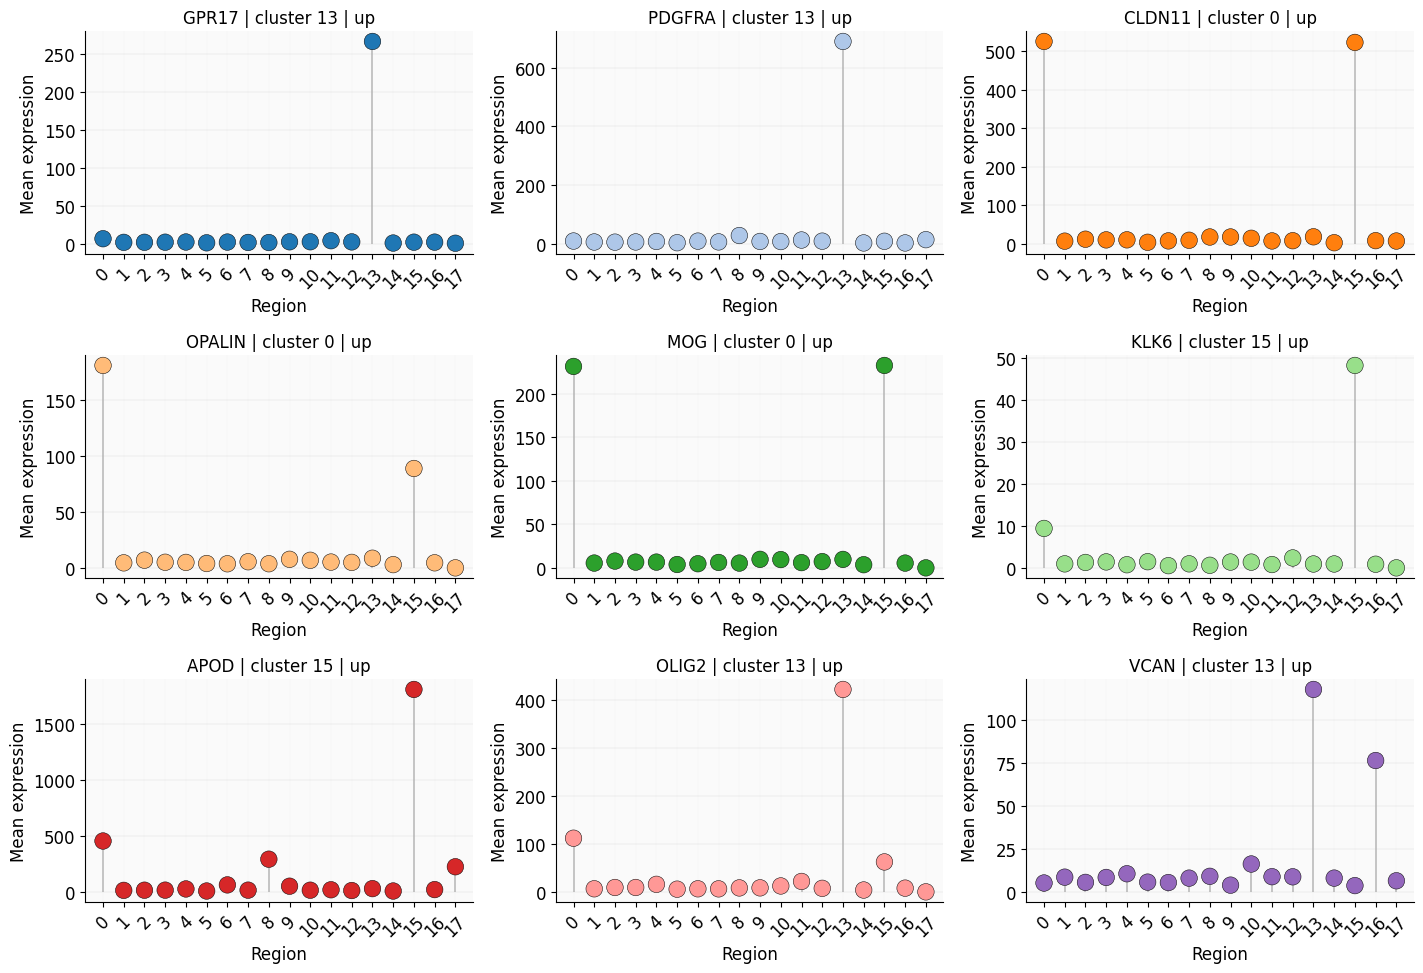

In [12]:
gene_table = make_gene_name_table(de_df["gene"].unique())
de_df_go = add_parsed_gene_names_to_de(de_df)
plt.rcParams['font.size'] = 12

regions_of_interest = [str(t) for t in regions_of_interest]#['0', '22', '29'] # This may change; I selected domains from the dotplot with dominant colors


top = (
    de_df_go
    .assign(region=lambda d: d["region"].astype(str),
            abs_log2fc=lambda d: d["log2fc"].abs(),
            direction=lambda d: np.where(d["log2fc"] >= 0, "up", "down"))
    .query("region in @regions_of_interest and p_adj < 0.05 and log2fc > 0.25")
    .sort_values(["p_adj", "log2fc"], ascending=[True, False])
    .drop_duplicates("gene")
    .head(9)
    .set_index("gene")
)

top["label"] = (top["human_symbol"].fillna(pd.Series(top.index, index=top.index))
                .map(clean_gene_for_enrichr)
                .fillna(pd.Series(top.index, index=top.index)))

fig, axes, df = plot_gene_lollipop_by_region(
    ad.concat(adata_all),
    genes=top.index.tolist(),
    region_key="pred_label_matchk",
    color_by="gene",
    gene_direction_map=top["direction"].to_dict(),
    gene_region_map=top["region"].to_dict(),
    gene_label_map=top["label"].to_dict(),
)
plt.show()

# We can also look at how they vary over time in each of the 3 regions

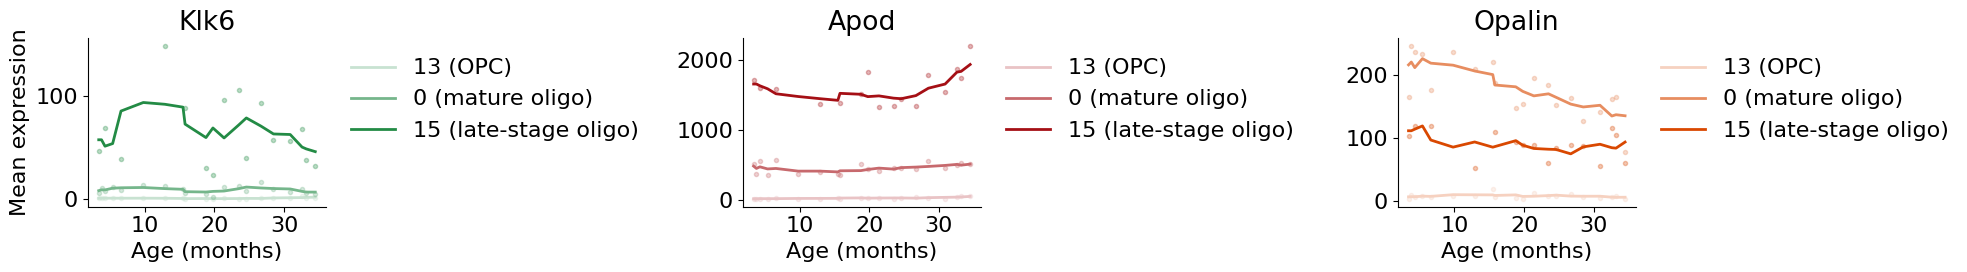

In [15]:
from downstream import plot_gene_dynamics_by_gene


# GENES = ["Pdgfra","Klk6", "Apod","Opalin"]
GENES = ["Klk6", "Apod","Opalin"]
cluster_names = {regions_of_interest[0]: regions_of_interest[0] + " (OPC)",
                         regions_of_interest[1]: regions_of_interest[1] + " (mature oligo)",
                         regions_of_interest[2]: regions_of_interest[2] + " (late-stage oligo)"}

plt.rcParams['font.size'] = 16

# gene_colors = {"Klk6": "#d94801", "Apod": "#a50f15", "Opalin": "#238b45"}#, "Pdgfra": "#4a90c4"}
gene_colors = {"Klk6":"#238b45", "Apod": "#a50f15", "Opalin": "#d94801"}#, "Pdgfra": "#4a90c4"}


fig, results = plot_gene_dynamics_by_gene(adata_all, timepoints, GENES, gene_colors = gene_colors, clusters = regions_of_interest,
    cluster_names=cluster_names, min_spots=10, smooth_window=5, figsize=(20,3), log1p=False) 
plt.show()

# Where is that small Oligo cluster from? We look at the coupling matrices

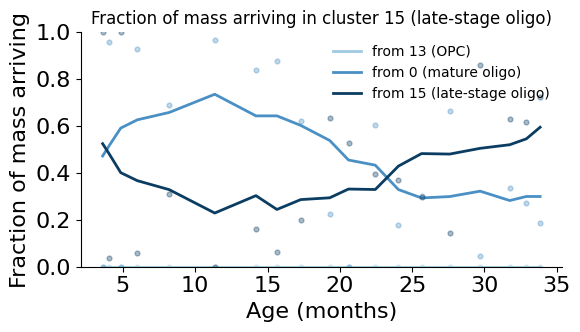

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from downstream import compute_transition_tables_from_couplings

regions_of_interest = [str(r) for r in regions_of_interest]
target  = regions_of_interest[-1]
sources = regions_of_interest

intervals = [f"{a:g}→{b:g}" for a, b in zip(timepoints[:-1], timepoints[1:])]

tables, _ = compute_transition_tables_from_couplings(
    adata_all, pi, celltype_key="pred_label_matchk", normalize="total"
)

inflow = pd.DataFrame(
    {iv: t.div(t.sum(axis=0).replace(0, np.nan), axis=1)[target]
     for iv, t in zip(intervals, tables)}
)
inflow.index = inflow.index.astype(str)

cluster_colors = dict(zip(regions_of_interest, ["#9ecae1", "#4a90c4", "#0b3d62"]))
labels = dict(zip(regions_of_interest, ["from 13 (OPC)",
                                        "from 0 (mature oligo)",
                                        "from 15 (late-stage oligo)"]))

tp   = np.asarray(timepoints, dtype=float)
ages = 0.5 * (tp[:-1] + tp[1:])

def smooth(y, w=8):
    y = np.asarray(y, dtype=float)
    return (pd.Series(y).rolling(w, center=True, min_periods=1).mean().to_numpy())

fig, ax = plt.subplots(figsize=(6.0, 3.6))

for s in sources:
    y = inflow.loc[s].to_numpy(dtype=float)
    ax.plot(ages, y, "o", ms=3.5, alpha=0.35, color=cluster_colors[s])
    ax.plot(ages, smooth(y), "-", lw=2, color=cluster_colors[s], label=labels[s])

ax.set_xlabel("Age (months)")
ax.set_ylabel("Fraction of mass arriving")
ax.set_title(f"Fraction of mass arriving in cluster {target} (late-stage oligo)",
             fontsize=12)
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=10, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

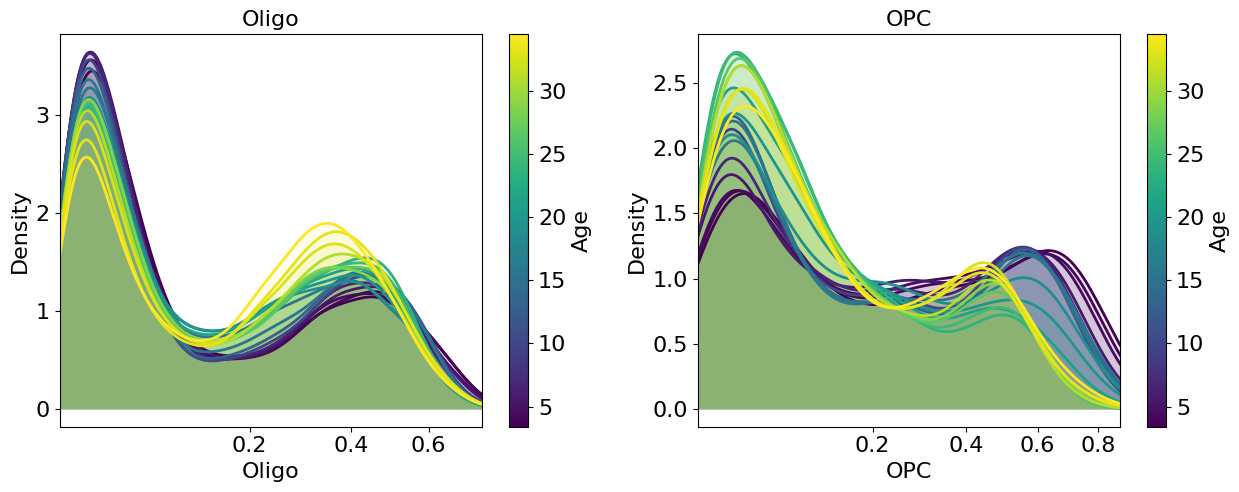

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import matplotlib.scale as mscale
import pickle

times = timepoints


def normalize_V(V):
    V = np.asarray(V, dtype=float)
    denom = np.sum(V, axis=1, keepdims=True) + 1e-12
    return V / denom


def plot_nonzero_V_histograms_on_ax(
    ax,
    times,
    V_list,
    celltype_idx,
    name,
    eps=1e-8,
    bins=40,
    density=True,
    alpha=0.18,
    cmap="viridis",
    x_quantile=0.995,
    use_kde=True,
    bandwidth=None,
    smooth_window=3,
    fill_alpha=0.08,
    xscale="sqrt",   # "linear", "sqrt", or "log"
):
    """
    Plot distribution of nonzero V coefficients for one component across time.
    KDE is fit in the transformed x-space so curves look correct on sqrt/log axes.
    """
    times_arr = np.asarray(times, dtype=float)
    order = np.argsort(times_arr)
    times_sorted = times_arr[order]
    V_sorted = [V_list[i] for i in order]

    # forward / inverse transforms
    if xscale == "sqrt":
        fwd = np.sqrt
        inv = lambda u: u ** 2
    elif xscale == "log":
        fwd = np.log10
        inv = lambda u: 10 ** u
    else:
        fwd = lambda x: x
        inv = lambda u: u

    # Extract nonzero values per (sorted) timepoint
    vals_by_time = []
    for Vi in V_sorted:
        vals = normalize_V(Vi)[:, celltype_idx]
        vals = np.asarray(vals, dtype=float)
        vals = vals[np.isfinite(vals)]
        vals = vals[vals > eps]
        vals_by_time.append(vals)

    nonempty_vals = [v for v in vals_by_time if len(v) > 0]
    if len(nonempty_vals) == 0:
        raise ValueError(f"No nonzero values found for {name} with eps={eps}")

    all_vals = np.concatenate(nonempty_vals)
    lo = float(np.min(all_vals))
    hi = float(np.quantile(all_vals, x_quantile))
    # transformed grid (smooth, evenly spaced in transformed space)
    u_lo, u_hi = fwd(lo), fwd(hi)
    u_pad = 0.05 * (u_hi - u_lo + 1e-12)
    u_grid = np.linspace(u_lo, u_hi + u_pad, 400)
    x_grid = inv(u_grid)

    norm = Normalize(vmin=times_sorted.min(), vmax=times_sorted.max())
    cmap_obj = plt.get_cmap(cmap)

    half = max(0, smooth_window // 2)
    n_t = len(times_sorted)

    summaries = []

    for i, t in enumerate(times_sorted):
        if len(vals_by_time[i]) == 0:
            continue

        lo_i = max(0, i - half)
        hi_i = min(n_t, i + half + 1)
        sigma = max(1.0, half)
        pooled, weights_used = [], []
        for j in range(lo_i, hi_i):
            if len(vals_by_time[j]) == 0:
                continue
            w = np.exp(-0.5 * ((j - i) / sigma) ** 2)
            pooled.append(vals_by_time[j])
            weights_used.append(np.full(len(vals_by_time[j]), w))

        if not pooled:
            continue

        vals_pooled = np.concatenate(pooled)
        weights_pooled = np.concatenate(weights_used)
        mask = (vals_pooled >= lo) & (vals_pooled <= inv(u_hi + u_pad))
        vals_pooled = vals_pooled[mask]
        weights_pooled = weights_pooled[mask]

        if len(vals_pooled) < 2:
            continue

        # KDE in transformed space
        u_pooled = fwd(vals_pooled)

        color = cmap_obj(norm(t))

        if use_kde and np.std(u_pooled) > 1e-12:
            try:
                kde = gaussian_kde(u_pooled, bw_method=bandwidth, weights=weights_pooled)
            except TypeError:
                kde = gaussian_kde(u_pooled, bw_method=bandwidth)
            y = kde(u_grid)
            ax.fill_between(x_grid, y, color=color, alpha=fill_alpha, linewidth=0)
            ax.plot(x_grid, y, color=color, linewidth=2, label=f"{t:g}")

        # ax.axvline(
        #     np.median(vals_by_time[i]),
        #     color=color, linewidth=1, alpha=0.35,
        # )

        summaries.append({
            "time": float(t),
            "n_nonzero": int(len(vals_by_time[i])),
            "nonzero_prop": len(vals_by_time[i]) / normalize_V(V_sorted[i]).shape[0],
            "mean_nonzero": float(np.mean(vals_by_time[i])),
            "median_nonzero": float(np.median(vals_by_time[i])),
        })

    # apply sqrt/log axis scale visually
    if xscale == "sqrt":
        # function scale: forward sqrt, inverse square
        ax.set_xscale("function", functions=(np.sqrt, np.square))
    elif xscale == "log":
        ax.set_xscale("log")

    ax.set_xlim(lo, inv(u_hi + u_pad))
    ax.set_xlabel(name)
    ax.set_ylabel("Density")
    ax.set_title(name, fontsize=16)

    sm = ScalarMappable(norm=norm, cmap=cmap_obj)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label("Age")

    return vals_by_time, summaries


# ---------- usage ----------
times_arr = np.asarray(times, dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=False)

oligo_vals, oligo_summary = plot_nonzero_V_histograms_on_ax(
    axes[0],
    times=times_arr,
    V_list=V,
    celltype_idx=2,
    name="Oligo",
    eps=1e-2,
    x_quantile=0.995,
    use_kde=True,
    smooth_window=5,
    xscale="sqrt",
)

opc_vals, opc_summary = plot_nonzero_V_histograms_on_ax(
    axes[1],
    times=times_arr,
    V_list=V,
    celltype_idx=18,
    name="OPC",
    eps=1e-2,
    x_quantile=0.995,
    use_kde=True,
    smooth_window=5,
    xscale="sqrt",
)

plt.tight_layout()
plt.show()
